# Kernel SVM from Scratch: Polynomial and RBF Kernels

**Goal:** build intuition for *why* kernels let a linear SVM draw curved decision boundaries, using only **NumPy** (matplotlib is used just for plots).

**Roadmap**
1. Synthetic datasets that a straight line cannot separate
2. The kernel idea: similarity = dot product in a hidden feature space
3. Polynomial kernel: intuition + explicit feature-map check
4. RBF kernel: intuition (similarity "bumps") + role of $\gamma$
5. A kernel SVM solver written from scratch (dual coordinate ascent)
6. Decision boundaries: linear vs polynomial vs RBF
7. Effect of hyperparameters ($d$, $\gamma$, $C$)
8. Sanity check against scikit-learn

**Notation:** $K(x,z)=\phi(x)^\top\phi(z)$, labels $y_i\in\{-1,+1\}$, soft-margin parameter $C$.

In [27]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
plt.rcParams["figure.dpi"] = 110

## 1. Synthetic data

We generate three 2D problems **from scratch** (no sklearn generators):

| Dataset | Shape | Which kernel should shine? |
|---|---|---|
| Linear blobs | two separated clouds | linear is enough |
| Circles | inner disk vs outer ring | polynomial (d=2) or RBF |
| Moons / XOR-like | interleaved or checkerboard classes | RBF (polynomial d=2 struggles on moons) |

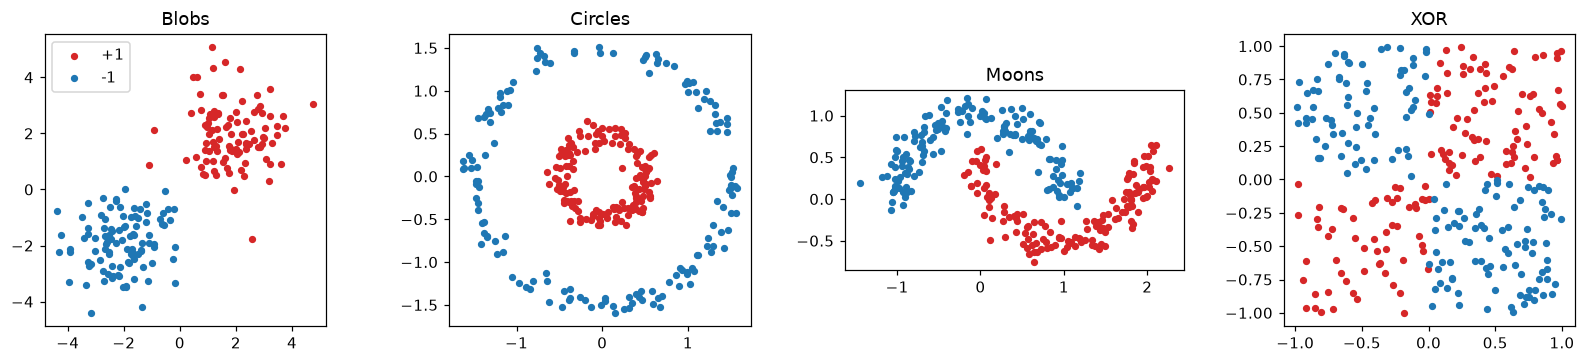

In [28]:
def make_blobs(n=200, seed=0):
    # Two Gaussian clouds -> linearly separable (mostly)
    rng = np.random.default_rng(seed)
    X1 = rng.normal([-2, -2], 1.0, size=(n // 2, 2))
    X2 = rng.normal([+2, +2], 1.0, size=(n // 2, 2))
    X = np.vstack([X1, X2])
    y = np.r_[-np.ones(n // 2), np.ones(n // 2)]
    return X, y

def make_circles(n=300, noise=0.08, seed=0):
    # Inner circle (class +1) and outer ring (class -1)
    rng = np.random.default_rng(seed)
    t = rng.uniform(0, 2 * np.pi, n)
    r = np.where(np.arange(n) < n // 2, 0.5, 1.5)           # radii
    X = np.c_[r * np.cos(t), r * np.sin(t)] + rng.normal(0, noise, (n, 2))
    y = np.where(np.arange(n) < n // 2, 1.0, -1.0)
    return X, y

def make_moons(n=300, noise=0.12, seed=0):
    # Two interleaving half-circles
    rng = np.random.default_rng(seed)
    m = n // 2
    t = rng.uniform(0, np.pi, m)
    upper = np.c_[np.cos(t), np.sin(t)]
    lower = np.c_[1 - np.cos(t), 0.5 - np.sin(t)]
    X = np.vstack([upper, lower]) + rng.normal(0, noise, (2 * m, 2))
    y = np.r_[-np.ones(m), np.ones(m)]
    return X, y

def make_xor(n=300, seed=0):
    # Checkerboard: class = sign(x1 * x2). Classic non-linear problem.
    rng = np.random.default_rng(seed)
    X = rng.uniform(-1, 1, size=(n, 2))
    y = np.sign(X[:, 0] * X[:, 1])
    y[y == 0] = 1
    return X, y

def train_test_split(X, y, test_frac=0.3, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(X))
    cut = int(len(X) * (1 - test_frac))
    tr, te = idx[:cut], idx[cut:]
    return X[tr], X[te], y[tr], y[te]

datasets = {
    "Blobs": make_blobs(),
    "Circles": make_circles(),
    "Moons": make_moons(),
    "XOR": make_xor(),
}

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, (name, (X, y)) in zip(axes, datasets.items()):
    ax.scatter(X[y == 1, 0], X[y == 1, 1], c="tab:red", s=14, label="+1")
    ax.scatter(X[y == -1, 0], X[y == -1, 1], c="tab:blue", s=14, label="-1")
    ax.set_title(name); ax.set_aspect("equal")
axes[0].legend()
plt.tight_layout(); plt.show()

## 2. The kernel idea in one paragraph

A linear SVM draws a hyperplane. If classes are tangled (circles, XOR), no hyperplane works in the original space.

**Trick:** lift the data with a map $\phi$ into a richer space where a hyperplane *does* work.
- Circles: add the feature $x_1^2+x_2^2$ (distance from origin). Now inner points have small values, outer points large, so one threshold separates them.

**Problem:** $\phi$ can be huge (RBF: infinite-dimensional). 

**Kernel trick:** the SVM dual only needs dot products $\phi(x_i)^\top\phi(x_j)$. A kernel function $K(x_i,x_j)$ returns that number directly from the original vectors, so we never compute $\phi$.

> **Intuition:** a kernel is a **similarity score**. Big value = "these two points look alike". The SVM then classifies a new point by asking *which support vectors is it similar to, and what are their labels?*

## 3. Kernel functions

Each function takes two matrices `A` (n×d) and `B` (m×d) and returns the **Gram matrix** (n×m) whose entry $(i,j)$ is $K(A_i, B_j)$. Vectorizing this avoids Python loops.

In [29]:
def linear_kernel(A, B):
    # K(x,z) = x . z
    # Intuition: plain similarity = how much two vectors point the same way.
    return A @ B.T

def polynomial_kernel(A, B, degree=3, gamma=1.0, coef0=1.0):
    # K(x,z) = (gamma * x.z + coef0)^degree
    # Intuition: considers ALL feature interactions up to `degree`
    #   (x1, x2, x1*x2, x1^2, ...) without ever building them.
    # - degree controls how wiggly/complex the boundary can be.
    # - coef0 > 0 keeps lower-order terms (otherwise only pure degree-d terms).
    return (gamma * (A @ B.T) + coef0) ** degree

def rbf_kernel(A, B, gamma=1.0):
    # K(x,z) = exp(-gamma * ||x - z||^2)
    # Intuition: similarity decays with distance. K=1 if x==z, K->0 far away.
    # - gamma is the "sharpness": large gamma = tiny neighbourhood (very local),
    #   small gamma = wide neighbourhood (smooth, almost linear).
    # Uses ||x-z||^2 = ||x||^2 + ||z||^2 - 2 x.z  for a loop-free computation.
    sq_A = np.sum(A ** 2, axis=1)[:, None]
    sq_B = np.sum(B ** 2, axis=1)[None, :]
    sq_dist = sq_A + sq_B - 2 * (A @ B.T)
    return np.exp(-gamma * np.maximum(sq_dist, 0))   # maximum() guards tiny negatives

### 3a. Polynomial kernel: what is hiding inside?

Take 2D inputs $x=(x_1,x_2)$ and the kernel $K(x,z)=(x^\top z)^2$ (degree 2, $\gamma=1$, coef0=0). Expanding:

$$(x_1z_1+x_2z_2)^2 = x_1^2z_1^2 + 2x_1x_2z_1z_2 + x_2^2z_2^2 = \phi(x)^\top\phi(z),\quad \phi(x)=\big(x_1^2,\ \sqrt2\,x_1x_2,\ x_2^2\big)$$

So the kernel secretly works in a **3D space of quadratic terms**. Let's verify numerically that both routes give the same number.

In [30]:
def phi_quadratic(x):
    # Explicit feature map for (x.z)^2 in 2D
    return np.array([x[0] ** 2, np.sqrt(2) * x[0] * x[1], x[1] ** 2])

x = np.array([1.0, 2.0])
z = np.array([3.0, -1.0])

k_trick    = polynomial_kernel(x[None, :], z[None, :], degree=2, gamma=1.0, coef0=0.0)[0, 0]
k_explicit = phi_quadratic(x) @ phi_quadratic(z)

print("Kernel trick  :", k_trick)
print("Explicit phi  :", k_explicit)
print("Equal?        :", np.isclose(k_trick, k_explicit))

Kernel trick  : 1.0
Explicit phi  : 0.9999999999999982
Equal?        : True


**Why this matters:** with 100 input features and degree 5 there are billions of monomials, yet the kernel costs one dot product and one power. 

Now see the lift working: for the circles data, the quadratic map makes the classes **linearly separable in 3D** (the $x_1^2+x_2^2$ direction is the "radius" feature).

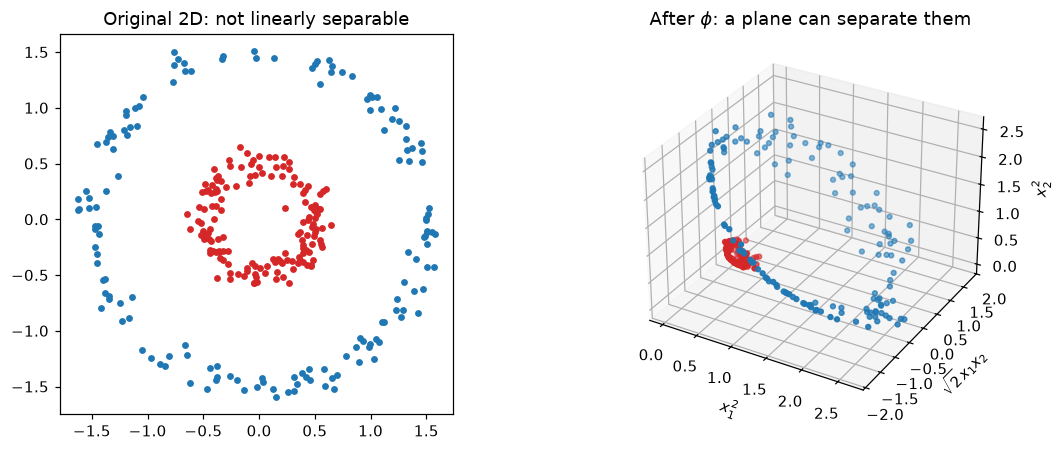

In [31]:
Xc, yc = datasets["Circles"]
Phi = np.array([phi_quadratic(p) for p in Xc])        # lift to 3D

fig = plt.figure(figsize=(11, 4.2))
ax1 = fig.add_subplot(1, 2, 1)
ax1.scatter(Xc[yc == 1, 0], Xc[yc == 1, 1], c="tab:red", s=12)
ax1.scatter(Xc[yc == -1, 0], Xc[yc == -1, 1], c="tab:blue", s=12)
ax1.set_title("Original 2D: not linearly separable"); ax1.set_aspect("equal")

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.scatter(*Phi[yc == 1].T, c="tab:red", s=10)
ax2.scatter(*Phi[yc == -1].T, c="tab:blue", s=10)
ax2.set_xlabel("$x_1^2$"); ax2.set_ylabel(r"$\sqrt{2}x_1x_2$"); ax2.set_zlabel("$x_2^2$")
ax2.set_title("After $\\phi$: a plane can separate them")
plt.tight_layout(); plt.show()

### 3b. RBF kernel: similarity bumps

$K(x,z)=\exp(-\gamma\|x-z\|^2)$ is a Gaussian "bump" centred on $z$.

- Distance 0 → similarity 1
- Far away → similarity ≈ 0
- $\gamma$ sets the **width of the bump**: width $\sim 1/\sqrt{\gamma}$

The SVM prediction $f(x)=\sum_i \alpha_i y_i K(x_i,x)+b$ is a **weighted sum of bumps**, one per support vector: positive bumps for $+1$ vectors, negative bumps for $-1$ vectors. The boundary is where the bumps cancel out. That's why RBF can wrap around any shape.

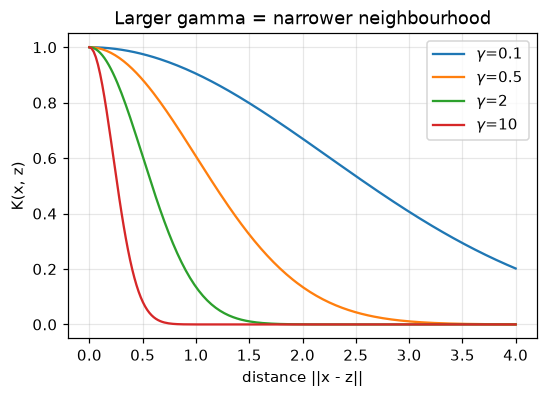

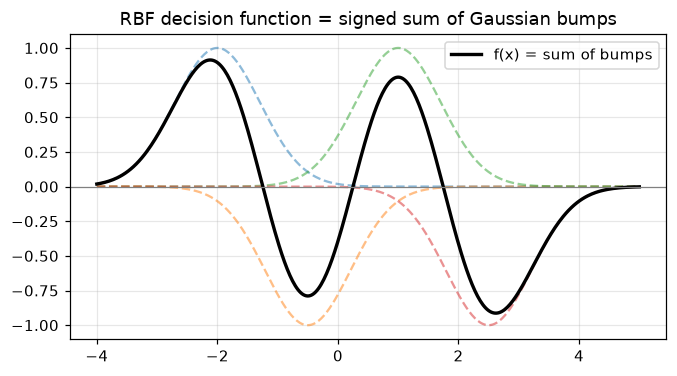

In [32]:
# (1) Similarity vs distance for different gamma
d = np.linspace(0, 4, 200)
plt.figure(figsize=(5.5, 3.6))
for g in [0.1, 0.5, 2, 10]:
    plt.plot(d, np.exp(-g * d ** 2), label=fr"$\gamma$={g}")
plt.xlabel("distance ||x - z||"); plt.ylabel("K(x, z)")
plt.title("Larger gamma = narrower neighbourhood"); plt.legend(); plt.grid(alpha=.3)
plt.show()

# (2) A tiny 1D example: sum of bumps builds a non-linear decision function
centers = np.array([-2.0, -0.5, 1.0, 2.5])
signs   = np.array([ 1.0, -1.0, 1.0, -1.0])      # pretend these are alpha_i * y_i
xs = np.linspace(-4, 5, 400)

plt.figure(figsize=(7, 3.6))
total = np.zeros_like(xs)
for c, s in zip(centers, signs):
    bump = s * np.exp(-1.0 * (xs - c) ** 2)
    total += bump
    plt.plot(xs, bump, "--", alpha=.5)
plt.plot(xs, total, "k", lw=2.2, label="f(x) = sum of bumps")
plt.axhline(0, c="gray", lw=.8)
plt.title("RBF decision function = signed sum of Gaussian bumps")
plt.legend(); plt.grid(alpha=.3); plt.show()

## 4. Kernel SVM from scratch

### Solver choice (kept simple on purpose)
The soft-margin dual is

$$\max_\alpha\ \sum_i\alpha_i-\tfrac12\sum_{i,j}\alpha_i\alpha_jy_iy_jK_{ij}\quad\text{s.t. } 0\le\alpha_i\le C,\ \ \sum_i\alpha_iy_i=0 .$$

The equality constraint (from the bias $b$) couples all variables, which is why full SMO updates *pairs*. 

**Simplification:** append a constant feature 1 to every point, i.e. use $K'(x,z)=K(x,z)+1$. The bias is absorbed into the model, the equality constraint disappears, and we can update **one $\alpha_i$ at a time** with a closed-form step (dual coordinate ascent):

$$\alpha_i \leftarrow \operatorname{clip}\!\Big(\alpha_i+\frac{1-y_i\sum_j\alpha_jy_jK'_{ij}}{K'_{ii}},\ 0,\ C\Big)$$

*Intuition:* if point $i$ currently has margin $y_if(x_i)<1$, increase its $\alpha_i$ (give it more influence); if the margin is comfortably $>1$, shrink $\alpha_i$ toward 0. The clip to $[0,C]$ is the "soft" part: nobody can have influence larger than $C$.

Prediction: $f(x)=\sum_i\alpha_iy_i\,(K(x_i,x)+1)$. Points with $\alpha_i>0$ are the **support vectors**.

In [33]:
class KernelSVM:
    # Soft-margin SVM in the dual, bias absorbed via K' = K + 1.

    def __init__(self, kernel, C=1.0, max_epochs=200, tol=1e-4, **kernel_params):
        self.kernel = kernel
        self.C = C
        self.max_epochs = max_epochs
        self.tol = tol
        self.kernel_params = kernel_params

    def _K(self, A, B):
        return self.kernel(A, B, **self.kernel_params) + 1.0     # +1 absorbs the bias

    def fit(self, X, y):
        n = len(X)
        K = self._K(X, X)                  # Gram matrix (n x n): ALL pairwise similarities
        alpha = np.zeros(n)
        f = np.zeros(n)                    # f_i = sum_j alpha_j y_j K_ij (kept up to date)
        diag = np.diag(K)
        self.history_ = []

        for epoch in range(self.max_epochs):
            max_change = 0.0
            for i in np.random.permutation(n):
                # How badly is point i violating its margin?  (1 - y f) > 0 means violation
                grad = 1.0 - y[i] * f[i]
                new_a = np.clip(alpha[i] + grad / diag[i], 0.0, self.C)
                delta = new_a - alpha[i]
                if delta != 0.0:
                    f += delta * y[i] * K[:, i]          # cheap incremental update of all f_j
                    alpha[i] = new_a
                    max_change = max(max_change, abs(delta))

            # Dual objective, handy for monitoring convergence
            dual = alpha.sum() - 0.5 * (alpha * y) @ K @ (alpha * y)
            self.history_.append(dual)
            if max_change < self.tol:
                break

        sv = alpha > 1e-8
        self.alpha_sv_ = alpha[sv]
        self.X_sv_ = X[sv]
        self.y_sv_ = y[sv]
        self.n_epochs_ = epoch + 1
        return self

    def decision_function(self, X):
        # f(x) = sum_{i in SV} alpha_i y_i K'(x_i, x)
        return self._K(X, self.X_sv_) @ (self.alpha_sv_ * self.y_sv_)

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1.0, -1.0)

    def score(self, X, y):
        return np.mean(self.predict(X) == y)

### Plot helper
Shows the decision boundary ($f=0$, solid), the margins ($f=\pm1$, dashed), and circles the support vectors.

In [34]:
def plot_boundary(model, X, y, ax=None, title=""):
    if ax is None:
        ax = plt.gca()
    pad = 0.4
    x_min, x_max = X[:, 0].min() - pad, X[:, 0].max() + pad
    y_min, y_max = X[:, 1].min() - pad, X[:, 1].max() + pad
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.decision_function(grid).reshape(xx.shape)

    ax.contourf(xx, yy, Z, levels=[-1e9, 0, 1e9], colors=["#cfe0f5", "#f7d4d4"], alpha=.8)
    ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors="k",
               linestyles=["--", "-", "--"], linewidths=[.8, 1.6, .8])
    ax.scatter(X[y == 1, 0], X[y == 1, 1], c="tab:red", s=12, edgecolor="none")
    ax.scatter(X[y == -1, 0], X[y == -1, 1], c="tab:blue", s=12, edgecolor="none")
    ax.scatter(model.X_sv_[:, 0], model.X_sv_[:, 1], s=55,
               facecolors="none", edgecolors="k", linewidths=.9)
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])

## 5. Linear vs Polynomial vs RBF on every dataset

Read the grid column by column:
- **Linear** works on blobs but is at or near chance on circles and XOR, and mediocre on moons.
- **Polynomial (d=2)** captures circles and XOR (both are quadratic shapes!) but bends poorly around moons.
- **RBF** adapts to all of them.

Titles show test accuracy and the number of support vectors (fewer SVs = simpler model).

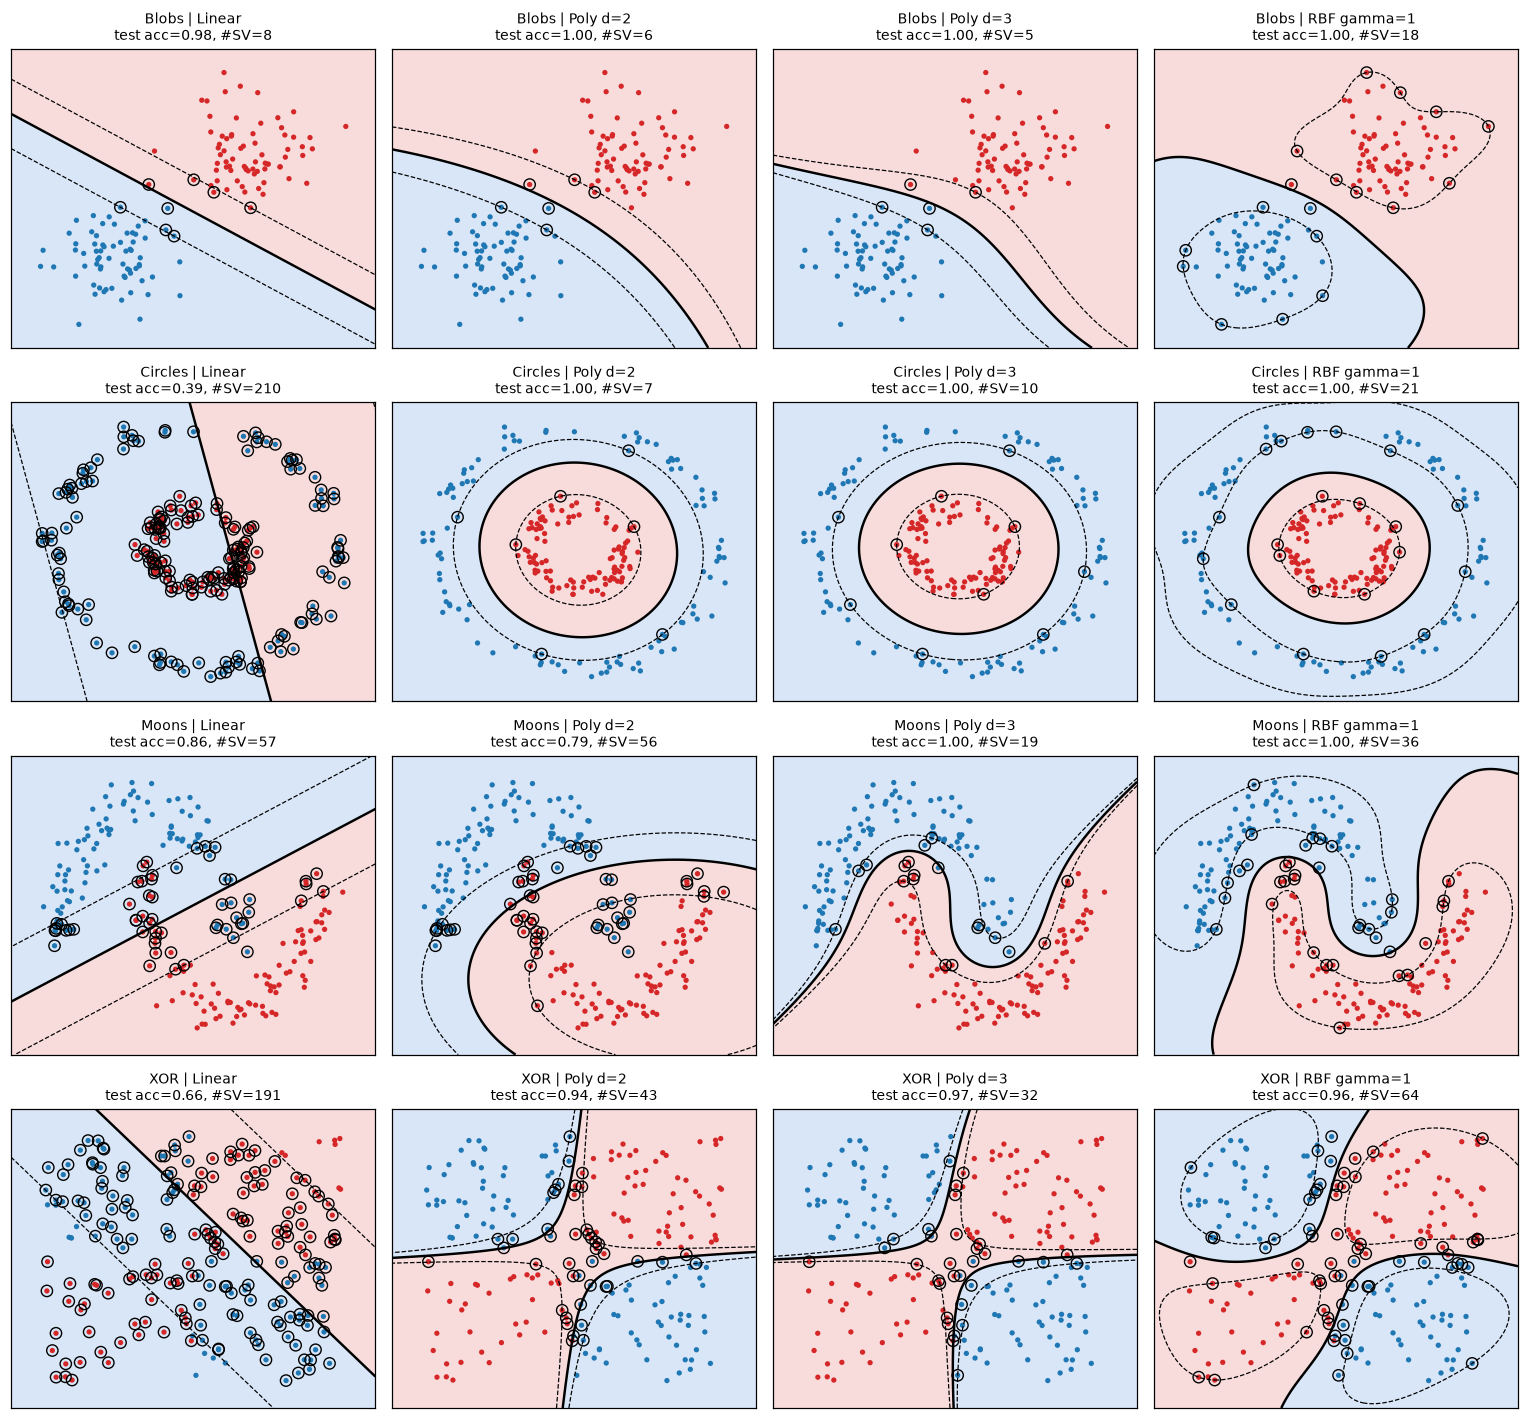

In [35]:
configs = [
    ("Linear",         linear_kernel,     dict()),
    ("Poly d=2",       polynomial_kernel, dict(degree=2, gamma=1.0, coef0=1.0)),
    ("Poly d=3",       polynomial_kernel, dict(degree=3, gamma=1.0, coef0=1.0)),
    ("RBF gamma=1",    rbf_kernel,        dict(gamma=1.0)),
]

fig, axes = plt.subplots(len(datasets), len(configs), figsize=(14, 13))
for r, (dname, (X, y)) in enumerate(datasets.items()):
    Xtr, Xte, ytr, yte = train_test_split(X, y)
    mu, sd = Xtr.mean(0), Xtr.std(0)                 # standardize with TRAIN stats only
    Xtr_s, Xte_s = (Xtr - mu) / sd, (Xte - mu) / sd

    for c, (kname, kfun, params) in enumerate(configs):
        model = KernelSVM(kfun, C=1.0, **params).fit(Xtr_s, ytr)
        acc = model.score(Xte_s, yte)
        plot_boundary(model, Xtr_s, ytr, ax=axes[r, c],
                      title=f"{dname} | {kname}\ntest acc={acc:.2f}, #SV={len(model.alpha_sv_)}")
plt.tight_layout(); plt.show()

## 6. Hyperparameters: where overfitting and underfitting come from

### 6a. RBF $\gamma$ (on the moons data)
- **Too small** → bumps are wide, everything is similar to everything → boundary almost linear (**underfit**).
- **Too large** → each point is an isolated island → boundary hugs individual samples (**overfit**; nearly every point becomes a support vector).

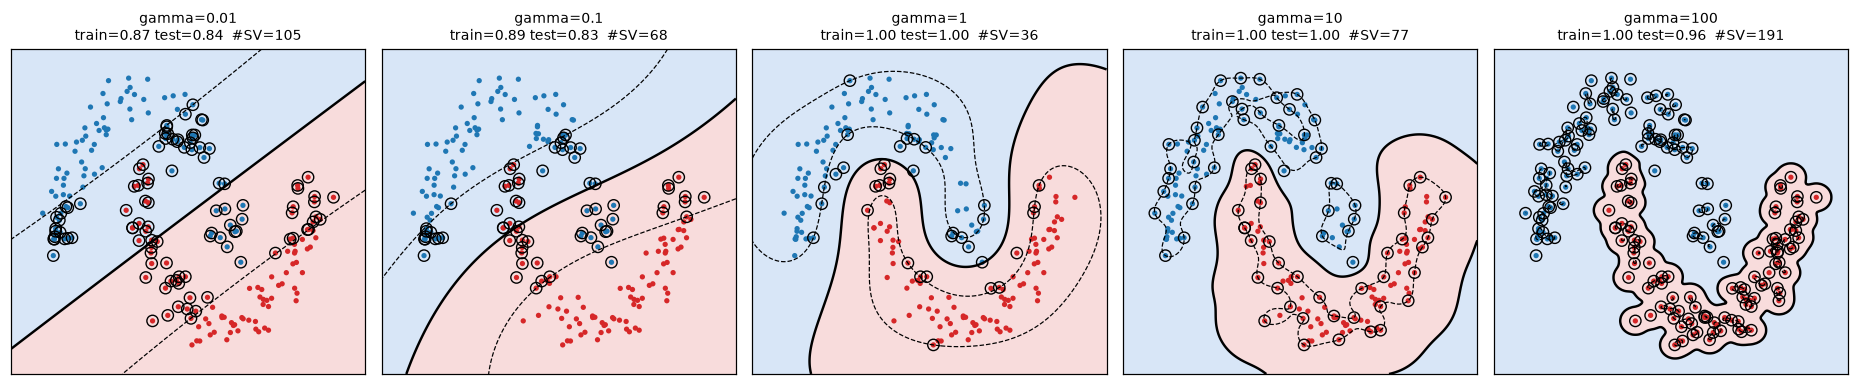

In [36]:
X, y = datasets["Moons"]
Xtr, Xte, ytr, yte = train_test_split(X, y)
mu, sd = Xtr.mean(0), Xtr.std(0)
Xtr_s, Xte_s = (Xtr - mu) / sd, (Xte - mu) / sd

gammas = [0.01, 0.1, 1, 10, 100]
fig, axes = plt.subplots(1, len(gammas), figsize=(17, 3.6))
for ax, g in zip(axes, gammas):
    m = KernelSVM(rbf_kernel, C=1.0, gamma=g).fit(Xtr_s, ytr)
    plot_boundary(m, Xtr_s, ytr, ax=ax,
                  title=f"gamma={g}\ntrain={m.score(Xtr_s, ytr):.2f} test={m.score(Xte_s, yte):.2f}  #SV={len(m.alpha_sv_)}")
plt.tight_layout(); plt.show()

### 6b. Polynomial degree (on the moons data)
Higher degree = more flexible curve, but also more risk of wild behaviour far from the data (polynomials blow up).

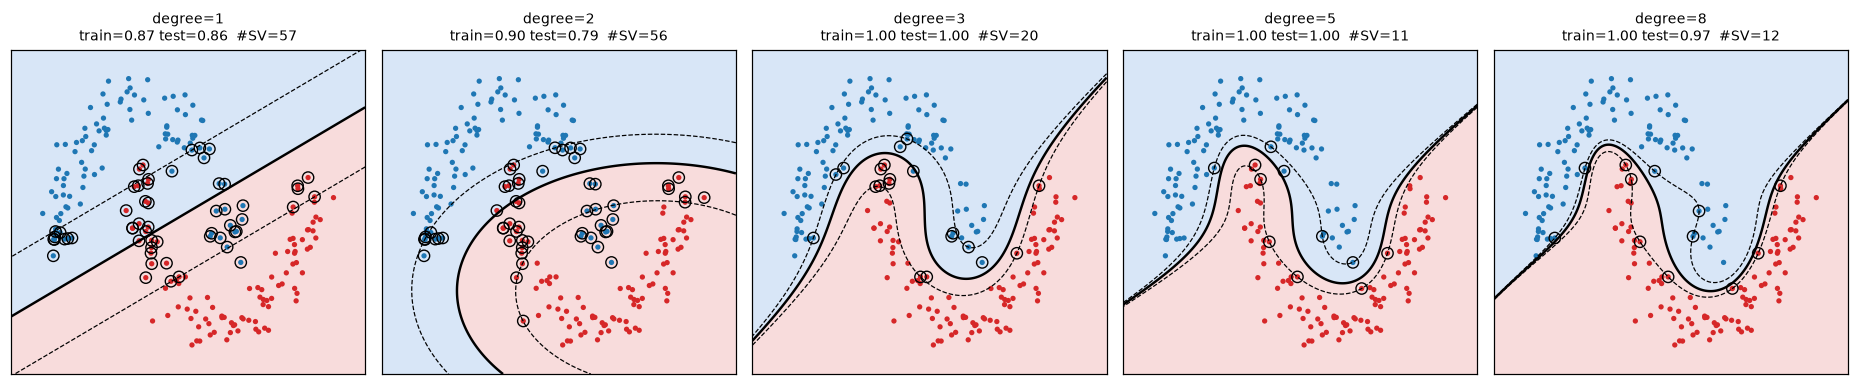

In [37]:
degrees = [1, 2, 3, 5, 8]
fig, axes = plt.subplots(1, len(degrees), figsize=(17, 3.6))
for ax, dg in zip(axes, degrees):
    m = KernelSVM(polynomial_kernel, C=1.0, degree=dg, gamma=1.0, coef0=1.0).fit(Xtr_s, ytr)
    plot_boundary(m, Xtr_s, ytr, ax=ax,
                  title=f"degree={dg}\ntrain={m.score(Xtr_s, ytr):.2f} test={m.score(Xte_s, yte):.2f}  #SV={len(m.alpha_sv_)}")
plt.tight_layout(); plt.show()

### 6c. Soft-margin $C$ (RBF, moons)
- **Small C** → margin violations are cheap → smoother boundary, more tolerance for noise.
- **Large C** → violations are expensive → boundary bends to classify every training point (risk of overfitting).

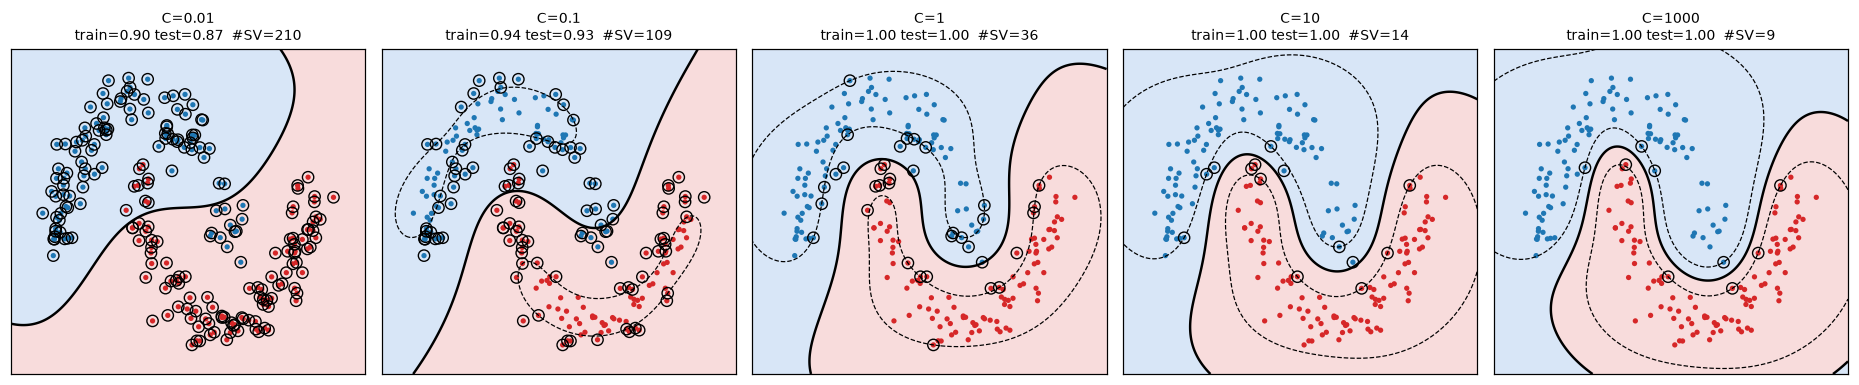

In [38]:
Cs = [0.01, 0.1, 1, 10, 1000]
fig, axes = plt.subplots(1, len(Cs), figsize=(17, 3.6))
for ax, Cv in zip(axes, Cs):
    m = KernelSVM(rbf_kernel, C=Cv, gamma=1.0, max_epochs=300).fit(Xtr_s, ytr)
    plot_boundary(m, Xtr_s, ytr, ax=ax,
                  title=f"C={Cv}\ntrain={m.score(Xtr_s, ytr):.2f} test={m.score(Xte_s, yte):.2f}  #SV={len(m.alpha_sv_)}")
plt.tight_layout(); plt.show()

## 7. Sanity check against scikit-learn

Our solver absorbs the bias into the kernel (slightly different regularization of $b$ than libsvm), so the models will not be *identical*, but accuracies and boundaries should be very close.

In [39]:
try:
    from sklearn.svm import SVC
    rows = []
    for dname in ["Circles", "Moons", "XOR"]:
        X, y = datasets[dname]
        Xtr, Xte, ytr, yte = train_test_split(X, y)
        mu, sd = Xtr.mean(0), Xtr.std(0)
        Xtr_s, Xte_s = (Xtr - mu) / sd, (Xte - mu) / sd

        ours_rbf = KernelSVM(rbf_kernel, C=1.0, gamma=1.0).fit(Xtr_s, ytr).score(Xte_s, yte)
        sk_rbf   = SVC(kernel="rbf", C=1.0, gamma=1.0).fit(Xtr_s, ytr).score(Xte_s, yte)
        ours_pol = KernelSVM(polynomial_kernel, C=1.0, degree=3, gamma=1.0, coef0=1.0).fit(Xtr_s, ytr).score(Xte_s, yte)
        sk_pol   = SVC(kernel="poly", C=1.0, degree=3, gamma=1.0, coef0=1.0).fit(Xtr_s, ytr).score(Xte_s, yte)
        rows.append((dname, ours_rbf, sk_rbf, ours_pol, sk_pol))

    print(f"{'dataset':<9}{'RBF ours':>10}{'RBF sk':>9}{'Poly ours':>11}{'Poly sk':>9}")
    for r in rows:
        print(f"{r[0]:<9}{r[1]:>10.3f}{r[2]:>9.3f}{r[3]:>11.3f}{r[4]:>9.3f}")
except ImportError:
    print("scikit-learn not installed; skip this check.")

dataset    RBF ours   RBF sk  Poly ours  Poly sk
Circles       1.000    1.000      1.000    1.000
Moons         1.000    1.000      1.000    1.000
XOR           0.956    0.956      0.967    0.967


## 8. Summary and cheat sheet

| | Polynomial | RBF |
|---|---|---|
| Formula | $(\gamma x^\top z+r)^d$ | $\exp(-\gamma\|x-z\|^2)$ |
| Hidden feature space | all monomials up to degree $d$ (finite) | infinite-dimensional |
| Similarity meaning | global: depends on angle and magnitude | local: depends on distance only |
| Key hyperparameters | $d$, $r$ (coef0), $\gamma$ | $\gamma$ |
| Strength | natural for smooth global shapes (quadratic, XOR) | flexible default for arbitrary shapes |
| Weakness | numerically unstable for large $d$; extrapolates wildly | sensitive to $\gamma$; needs feature scaling |

**Rules of thumb**
1. Always **standardize** features before using kernels.
2. Start with **RBF** and tune $C,\gamma$ by cross-validation (log-scale grid, e.g. $10^{-2}\dots10^{3}$).
3. Many support vectors relative to $N$ (or train acc ≫ test acc) means **overfitting**: reduce $\gamma$ or $C$.
4. Use **linear** when the number of features is huge compared to samples; it scales far better.

**Exercises**
- Implement the **sigmoid** kernel and see why it is not always a valid (PSD) kernel.
- Check that the Gram matrix is positive semi-definite: `np.linalg.eigvalsh(K).min() >= -1e-8`.
- Add a **multi-class** wrapper (one-vs-rest) on top of `KernelSVM`.
- Replace coordinate ascent with a full **SMO** that keeps $b$ separate.